In [1]:
%load_ext autoreload
%autoreload 2
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'

import sys
import numpy as np
from IPython.display import display

code_path = "../src" # linux
sys.path.append(code_path)
sys.path.append(code_path+"/src")

import utilities as util
from anony_interface import ANInference
from xai_vad_zsac_interface import ADXAIDetector
from xai_vad_zsam_interface import GRAD4VAD_XAI_PPA
from xai_vad_zsad_interface import ADXAIVLMInference
from config import config as cfg

%matplotlib inline

# Installation

In [ ]:
!git clone https://github.com/muleina/XAVAD.git

In [ ]:
!pip install -e XAVAD/

# Load Models and Configs

In [2]:
# Configs
video_chunck_freq = 16  # XAI eval runs every 16 video frames 

## Load MASKING ZSAN: Anonymization

In [3]:
# ZSAN interface Config
zsan_kwargs = {'anony_method': 'mask',
                'detector_name': 'body__yolo',
                'detector_version': 'yolov8m-seg',
                'detector_imgsz': None,
                'detection_thr': 0.15,
                'detection_classes': [0] # person
                }
ANObj = ANInference(**zsan_kwargs)

init_anonymizer...
{'detector_name': 'body__yolo', 'kwargs_anony_method': {'color_format': 'bgr', 'alpha': 1.0, 'color': '#000000', 'preprocessors_list': [], 'postprocessors_list': []}, 'kwargs_detector_method': {'seg_type': 'instant', 'classes': [0], 'detector_version': 'yolov8m-seg', 'detection_thr': 0.15, 'imgsz': None, 'sahi_kwargs': None, 'device': 'cuda'}, 'target_resolution': None, 'isreset_cache': True}
loading object detector...
{'anony_type': 'body', 'seg_type': 'instant', 'classes': [0], 'detector_version': 'yolov8m-seg', 'detection_thr': 0.15, 'imgsz': None, 'sahi_kwargs': None, 'device': 'cuda'}
model:  yolov8m-seg
{'method': <function ConventionalImageAnonymizer.silhoutte at 0x7fb4df1f53a0>, 'kwargs': {'color_format': 'bgr', 'alpha': 1.0, 'color': '#000000', 'preprocessors_list': [], 'postprocessors_list': []}}


## Load XAI ZSAC: CLIP

In [4]:
# XAI ZSAC interface Config
zsac_kwargs = {'clip_modelname': 'ViT-L/14',
            'pooling_method': 'max',
            'prompt_concept_json_filepath': '../src/model/clip/llmv2_xd-concept.json',
            'prompt_feature_np_filepath': '../src/model/clip/anml_class_prompt_clip_features_norm_llmv2_xd_ViTL14.npy',
            'similarity_metric': 'cosine_softmax',
            'isreturn_max_indices': True
            }

ADXAIObj = ADXAIDetector(device="cuda", **zsac_kwargs)

xai_class_name_mapper = dict(zip(ADXAIObj.clip4vadObj.anml_class_names, range(len(ADXAIObj.clip4vadObj.anml_class_names))))

CLIP4VAD_XAI init...
Model parameters: 427616513
Input resolution: 224
Kernel size: (14, 14)
Context length: 77
Vocab size: 49408
Pooling method: max
CLIP image preprocess function:  Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x7fb4df03f920>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)
Loading Pre-computed Normalized CLIP text embedding....
CLIP Prompt Anomaly Categories: ['nonviolence', 'abuse', 'car_accident', 'explosion', 'fight', 'riot', 'shooting']
anml_class_prompt_clip_features_norm: torch.Size([768, 7])


## Load XAI ZSAM: PPA + Grad-ECLIP

In [5]:
# XAI ZSAM interface Config
zsam_kwargs = {'autofocus_method': 'ppa_patch_clipcat_gradmap_xai',
                'bbox_conf': 0.5,
                'ismultibox': False,
                'grad_mode': 'grad_eclip',
                'map_score_thr_dict': {'map_score_min': 0.05,
                'map_score_max': 0.5,
                'map_norm_score_min': 0.3},
                'patch_size': 448,
                'step_size': 336,
                'image_resize_wh': None
            }
                                        
ADXAIMAP_PPA_Obj = GRAD4VAD_XAI_PPA(ADXAIObj=ADXAIObj, device="cuda")

MAP anml_text_prompt_embedding: torch.Size([768, 7])
Processing GRAD4VAD_XAI.__init__: 
GRAD4VAD_XAI.__init__ is done!


## Load ZSAD: VLM

In [6]:
print("loading: VLM model and setting config")
# XAI VLM interface Config
vlm_kwargs = { "model": "blaifa/InternVL3_5:8b",
                "prompt_json_filename":"pmt_v2_ucf_xd_list.json",
              # "prompt_json_filename":"pmt_v1.json",
                "num_ctx": None, 
                # restrict to factual
                "temperature": 0.0, # keep it deterministic and factual < 0.3
                "top_p": 0.90, # keep it deterministic and select most probable token, [0.90--0.95]
                "top_k":10, # keep it deterministic and select most probable token
                "repeat_penalty": 1.0, # penalize repeated tokens
                # latency
                "target_resolution": None, # target resolution for video frames, (240, 240) is a good trade-off between speed and accuracy
                "num_frames": 16, # number of frames to process 
                "num_predict": 300, # output length, "max_tokens" is not supported in Ollama API, use "num_predict" instead,
            }

video_chunck_freq = 16

# XAI VLM Model (Ollama backend,  5-minute retrigger reload )
vlmvadObj = ADXAIVLMInference(keep_alive="5m", **vlm_kwargs)

loading: VLM model and setting config
Loading VLM model...
system prompt length: 2945
user prompt length: 735
**************************************************


## Utils

In [7]:
def xavad_xai_inference(video_filepath: str, video_frames: util.List[np.ndarray], is_masked_an=False, issave=True) -> None:
    video_filename = util.Path(video_filepath).name
    result_dirpath = util.Path(f"{cfg.result_path}/{video_filename}")
    result_dirpath.mkdir(parents=True, exist_ok=True)
    result_dirpath = str(result_dirpath)
    for i in range(0, len(video_frames) - video_chunck_freq, video_chunck_freq):
        print("#"*30 + f"Video Clip Snippet idx {i}:{i + video_chunck_freq}" + "#"*30)
        
        video_clip_chunk = video_frames[i:i+video_chunck_freq]
        display(util.show_video_on_nb(video_clip_chunk, video_meta, input_format="BGR", width=480, height=360))
        
        result_filename_tag = f"{video_filename}__idx{i}_{i + video_chunck_freq}"
        
        # ZSAC Inference
        print("*"*30 + f"VAD XAI using ZSAC" + "*"*30)
        pred_zsac_topk, _, similarity_scores = ADXAIObj.inference(video_clip_chunk, 
                                                                                                video_metadata=video_meta,
                                                                                                video_chunck_freq=video_chunck_freq,
                                                                                                top_k=3, 
                                                                                                video_clip_features_norm=None
                                                                                            )
        print("="*30 + f"RESULT" + "="*30)
        print(pred_zsac_topk)
        pred_anml_category = list(pred_zsac_topk.keys())[0]    
        pred_anml_category_idx = xai_class_name_mapper[pred_anml_category]
        condidate_localized_frame_idx = similarity_scores[1].squeeze()[pred_anml_category_idx]
        condidate_localized_frame = video_clip_chunk[condidate_localized_frame_idx]
        print(f"pred_anml_category: {pred_anml_category}, pred_anml_category_idx: {pred_anml_category_idx}, condidate_localized_frame_idx: {condidate_localized_frame_idx}")
        
        # store ZSAC result
        if issave:
            util.save_json(data={"pred_zsac_topk":pred_zsac_topk, "pred_anml_category": pred_anml_category, "pred_anml_category_idx": pred_anml_category_idx, "condidate_localized_frame_idx": condidate_localized_frame_idx}, 
                    filename=f"ZSAC__AN{is_masked_an}__{result_filename_tag}.json", filepath=result_dirpath, sort_keys=False)
            
        # ZSAM Inference
        print("*"*30 + f"VAD XAI using ZSAM" + "*"*30)
        boxes_xyxy, fig_pil = ADXAIMAP_PPA_Obj.predict(util.cv2.cvtColor(condidate_localized_frame, util.cv2.COLOR_BGR2RGB), 
                                                    xai_cat_name=pred_anml_category, 
                                                        isplot=True,
                                                    **zsam_kwargs
                                        )
        print("="*30 + f"RESULT" + "="*30)
        display(fig_pil)
        
        # store ZSAM result
        if issave:
            fig_pil.save(f"{result_dirpath}/ZSAM_AN{is_masked_an}__{result_filename_tag}.jpg", format="JPEG")
        
        # ZSAD Inference
        print("*"*30 + f"VAD XAI using ZSAD" + "*"*30)
        xai_vlm_result_dict = vlmvadObj.inference(video_clip_chunk, 
                                        **vlm_kwargs 
                                        )
        print("="*30 + f"RESULT" + "="*30)
        print(xai_vlm_result_dict)
        
        # store ZSAD result
        if issave:
            util.save_json(data=xai_vlm_result_dict, 
                        filename=f"ZSAD__AN{is_masked_an}__{result_filename_tag}.json", filepath=result_dirpath)
        
        # break

# XAVAD Inference on No-AN Video

## Load Test Video Dataset

In [9]:
video_filepath = r"../data/XD_Violence/Fast.Five.2011__#00-32-56_00-33-26_label_B2-0-0.mp4"

video_frames, video_meta = util.videofile_loader(video_filepath, start_sec=0, 
                                                 clip_duration=None, 
                                                 fps=5, 
                                                #  target_resolution=(240, 240)
                                                )
print("video_meta: ", video_meta)
util.show_video_on_nb(video_frames, video_meta, input_format="BGR", width=480, height=360)

t:   0%|          | 0/151 [00:00<?, ?it/s, now=None]

videofile_loader...
process time: 0.16139 seconds.
loaded frame duration: 30.13 secs, frame length: 151, fps: 5, resolution: (136, 320, 3)
video_meta:  {'num_frames': 151, 'fps': 5, 'duration': 30.13, 'frame_size': (136, 320, 3)}


## XAVAD E2E Inference

##############################Video Clip Snippet idx 0:16##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


  0%|          | 0/16 [00:00<?, ?it/s]

100%|██████████| 16/16 [00:00<00:00, 191.37it/s]


CLIP encoding video frames...


...

Getting class names from labels, video_chunck_freq: 16
CLIP4VAD_XAI.inference is done!
process time: 1.2046 seconds.
==============================RESULT==============================
{'shooting': 0.77581, 'abuse': 0.09614, 'nonviolence': 0.07331}
pred_anml_category: shooting, pred_anml_category_idx: 6, condidate_localized_frame_idx: 3
******************************VAD XAI using ZSAM******************************
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (136, 320, 3)
xai_cat_name: shooting, xai_class_idx: 6
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (136, 320, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 1
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 1, device: cuda, video_chunck_freq: 1, pooling_method: max
video frames preprocessing...


100%|██████████| 1/1 [00:00<00:00, 14.81it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00,  6.72it/s]


Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.22758 seconds.
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.65317 seconds.
==============================RESULT==============================


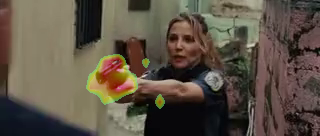

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 5.7982 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'gun shooting', 'reason': 'A person is pointing a gun at another individual in a confrontational manner, indicating a potential threat or violent situation.'}
##############################Video Clip Snippet idx 16:32##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 226.29it/s]


CLIP encoding video frames...


...

Getting class names from labels, video_chunck_freq: 16
CLIP4VAD_XAI.inference is done!
process time: 0.17848 seconds.
==============================RESULT==============================
{'shooting': 0.99161, 'abuse': 0.00393, 'fight': 0.0027}
pred_anml_category: shooting, pred_anml_category_idx: 6, condidate_localized_frame_idx: 8
******************************VAD XAI using ZSAM******************************
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (136, 320, 3)
xai_cat_name: shooting, xai_class_idx: 6
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (136, 320, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 1
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 1, device: cuda, video_chunck_freq: 1, pooling_method: max
video frames preprocessing...


100%|██████████| 1/1 [00:00<00:00, 91.51it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 72.67it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.029648 seconds.
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.056181 seconds.
==============================RESULT==============================


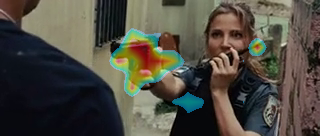

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 5.5371 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'arrest', 'reason': 'A person in a police uniform is pointing a firearm at another individual, indicating a potential arrest or confrontation.'}
##############################Video Clip Snippet idx 32:48##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 218.57it/s]


CLIP encoding video frames...


...

Getting class names from labels, video_chunck_freq: 16
CLIP4VAD_XAI.inference is done!
process time: 0.14408 seconds.
==============================RESULT==============================
{'abuse': 0.37903, 'explosion': 0.25839, 'fight': 0.1917}
pred_anml_category: abuse, pred_anml_category_idx: 1, condidate_localized_frame_idx: 3
******************************VAD XAI using ZSAM******************************
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (136, 320, 3)
xai_cat_name: abuse, xai_class_idx: 1
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (136, 320, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 1
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 1, device: cuda, video_chunck_freq: 1, pooling_method: max
video frames preprocessing...


100%|██████████| 1/1 [00:00<00:00, 364.82it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 71.28it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.021795 seconds.
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.04624 seconds.
==============================RESULT==============================


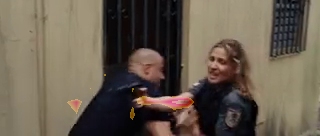

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 5.3878 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'arrest', 'reason': 'A person is being apprehended by another individual in a confrontational manner, with visible struggle and use of force.'}
##############################Video Clip Snippet idx 48:64##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 193.91it/s]


CLIP encoding video frames...


...

100%|██████████| 1/1 [00:00<00:00, 303.82it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 72.51it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.021131 seconds.


GRAD4VAD_XAI_PPA.predict is done!
process time: 0.047666 seconds.
==============================RESULT==============================


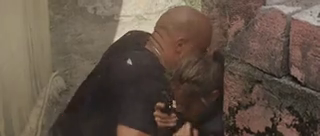

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 5.6433 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'abuse', 'reason': 'The video shows a person restraining another individual against a wall, which may indicate a form of physical control or abuse.'}
##############################Video Clip Snippet idx 64:80##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 207.04it/s]


CLIP encoding video frames...


...

Getting class names from labels, video_chunck_freq: 16
CLIP4VAD_XAI.inference is done!
process time: 0.19233 seconds.
==============================RESULT==============================
{'shooting': 0.82043, 'abuse': 0.0915, 'fight': 0.0681}
pred_anml_category: shooting, pred_anml_category_idx: 6, condidate_localized_frame_idx: 14
******************************VAD XAI using ZSAM******************************
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (136, 320, 3)
xai_cat_name: shooting, xai_class_idx: 6
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (136, 320, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 1
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 1, device: cuda, video_chunck_freq: 1, pooling_method: max
video frames preprocessing...


100%|██████████| 1/1 [00:00<00:00, 396.92it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 70.50it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.022992 seconds.
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.048115 seconds.
==============================RESULT==============================


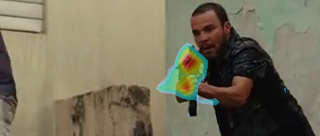

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 5.9954 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'assault', 'reason': 'The video shows two individuals in close proximity, appearing to be engaged in a physical altercation. The scene includes aggressive body language and potential physical contact, indicating a possible assault. The environment suggests a confrontational situation.'}
##############################Video Clip Snippet idx 80:96##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 229.88it/s]


CLIP encoding video frames...


...

Getting class names from labels, video_chunck_freq: 16
CLIP4VAD_XAI.inference is done!
process time: 0.17969 seconds.
==============================RESULT==============================
{'shooting': 0.86524, 'fight': 0.07961, 'riot': 0.02268}
pred_anml_category: shooting, pred_anml_category_idx: 6, condidate_localized_frame_idx: 0
******************************VAD XAI using ZSAM******************************
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (136, 320, 3)
xai_cat_name: shooting, xai_class_idx: 6
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (136, 320, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 1
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 1, device: cuda, video_chunck_freq: 1, pooling_method: max
video frames preprocessing...


100%|██████████| 1/1 [00:00<00:00, 341.95it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 72.29it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.022266 seconds.
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.057778 seconds.
==============================RESULT==============================


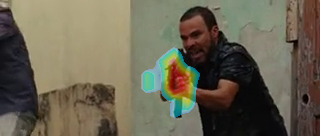

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 5.4849 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'arson', 'reason': 'Multiple individuals are seen holding firearms and advancing aggressively in a residential area, suggesting a potential threat or violent activity.'}
##############################Video Clip Snippet idx 96:112##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 199.83it/s]


CLIP encoding video frames...


...

Getting class names from labels, video_chunck_freq: 16
CLIP4VAD_XAI.inference is done!
process time: 0.18821 seconds.
==============================RESULT==============================
{'fight': 0.50279, 'shooting': 0.27596, 'abuse': 0.11077}
pred_anml_category: fight, pred_anml_category_idx: 4, condidate_localized_frame_idx: 1
******************************VAD XAI using ZSAM******************************
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (136, 320, 3)
xai_cat_name: fight, xai_class_idx: 4
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (136, 320, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 1
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 1, device: cuda, video_chunck_freq: 1, pooling_method: max
video frames preprocessing...


100%|██████████| 1/1 [00:00<00:00, 271.53it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 65.62it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.026496 seconds.
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.053823 seconds.
==============================RESULT==============================


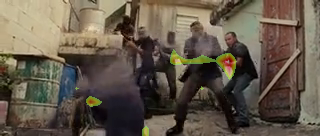

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 6.3049 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'arson', 'reason': 'The video shows a group of individuals in a confrontational stance, with some holding what appear to be weapons. There is visible smoke or dust in the air, suggesting a disturbance or potential fire. The scene is chaotic and suggests a violent or criminal activity.'}
##############################Video Clip Snippet idx 112:128##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 174.13it/s]


CLIP encoding video frames...


...

100%|██████████| 1/1 [00:00<00:00, 422.64it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 76.11it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.019944 seconds.


GRAD4VAD_XAI_PPA.predict is done!
process time: 0.045815 seconds.
==============================RESULT==============================


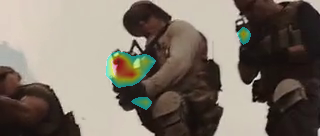

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 5.8299 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'assault', 'reason': 'The video shows a person being physically attacked by another individual on a set of stairs. The attacker is seen striking the victim, who is falling down the stairs. This indicates a violent altercation.'}
##############################Video Clip Snippet idx 128:144##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 178.06it/s]


CLIP encoding video frames...


...

Getting class names from labels, video_chunck_freq: 16
CLIP4VAD_XAI.inference is done!
process time: 0.17806 seconds.
==============================RESULT==============================
{'abuse': 0.68509, 'nonviolence': 0.13539, 'shooting': 0.11683}
pred_anml_category: abuse, pred_anml_category_idx: 1, condidate_localized_frame_idx: 6
******************************VAD XAI using ZSAM******************************
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (136, 320, 3)
xai_cat_name: abuse, xai_class_idx: 1
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (136, 320, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 1
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 1, device: cuda, video_chunck_freq: 1, pooling_method: max
video frames preprocessing...


100%|██████████| 1/1 [00:00<00:00, 384.45it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 76.20it/s]


Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.019775 seconds.
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.043376 seconds.
==============================RESULT==============================


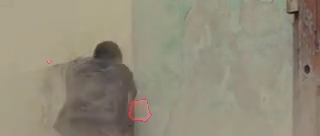

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 
ADXAIVLMInference.inference is done!
process time: 5.9033 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'arrest', 'reason': 'A person is seen holding a firearm against a wall, followed by armed individuals in tactical gear engaging in what appears to be a coordinated operation, suggesting a potential arrest or security intervention.'}


In [9]:
xavad_xai_inference(video_filepath, video_frames, is_masked_an=False, issave=True)

# XAVAD Inference on MASKED-AN Video

## Visual Anonymization

In [11]:
success, video_frames_anonymized = ANObj.inference(video_frames, num_workers=1)
if success:
    util.show_video_on_nb(video_frames_anonymized, video_meta, input_format="BGR", width=480, height=360)

ANInference.inference: 
Processing ANInference.inference: 


ANInference.inference is done!
process time: 2.2033 seconds.


## XAVAD E2E Inference

##############################Video Clip Snippet idx 0:16##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


  0%|          | 0/16 [00:00<?, ?it/s]

100%|██████████| 16/16 [00:00<00:00, 145.26it/s]


CLIP encoding video frames...


...

Getting class names from labels, video_chunck_freq: 16
CLIP4VAD_XAI.inference is done!
process time: 0.25895 seconds.
==============================RESULT==============================
{'shooting': 0.77967, 'abuse': 0.18634, 'nonviolence': 0.02394}
pred_anml_category: shooting, pred_anml_category_idx: 6, condidate_localized_frame_idx: 2
******************************VAD XAI using ZSAM******************************
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (136, 320, 3)
xai_cat_name: shooting, xai_class_idx: 6
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (136, 320, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 1
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 1, device: cuda, video_chunck_freq: 1, pooling_method: max
video frames preprocessing...


100%|██████████| 1/1 [00:00<00:00, 215.81it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 27.05it/s]


Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.049138 seconds.
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.16976 seconds.
==============================RESULT==============================


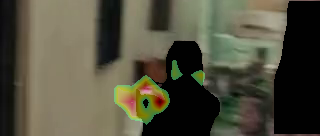

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 5.529 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'arrest', 'reason': 'Two individuals are seen in close proximity, with one appearing to restrain the other against a wall. The scene suggests a potential arrest or detainment due to the physical interaction.'}
##############################Video Clip Snippet idx 16:32##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 238.40it/s]


CLIP encoding video frames...


...

100%|██████████| 1/1 [00:00<00:00, 375.09it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 42.27it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.037114 seconds.


GRAD4VAD_XAI_PPA.predict is done!
process time: 0.072932 seconds.
==============================RESULT==============================


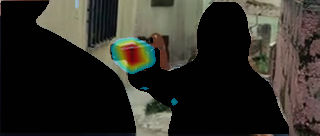

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 5.7254 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'gun shooting', 'reason': 'Two individuals are seen in silhouette, one holding a firearm and aiming it. The presence of a weapon and the stance suggest a potential threat or violent activity.'}
##############################Video Clip Snippet idx 32:48##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 196.48it/s]


CLIP encoding video frames...


...

Getting class names from labels, video_chunck_freq: 16
CLIP4VAD_XAI.inference is done!
process time: 0.16994 seconds.
==============================RESULT==============================
{'abuse': 0.7938, 'fight': 0.07863, 'nonviolence': 0.05801}
pred_anml_category: abuse, pred_anml_category_idx: 1, condidate_localized_frame_idx: 3
******************************VAD XAI using ZSAM******************************
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (136, 320, 3)
xai_cat_name: abuse, xai_class_idx: 1
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (136, 320, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 1
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 1, device: cuda, video_chunck_freq: 1, pooling_method: max
video frames preprocessing...


100%|██████████| 1/1 [00:00<00:00, 400.45it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 44.20it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.030092 seconds.
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.067781 seconds.
==============================RESULT==============================


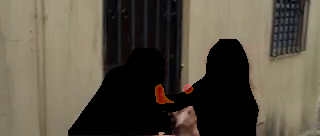

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 5.7883 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'arson', 'reason': 'The video shows individuals in dark clothing approaching a building, followed by smoke and what appears to be an explosion or fire. The actions suggest an attempt to set the building on fire.'}
##############################Video Clip Snippet idx 48:64##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 148.52it/s]


CLIP encoding video frames...


...

100%|██████████| 1/1 [00:00<00:00, 221.20it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 43.18it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.033736 seconds.


GRAD4VAD_XAI_PPA.predict is done!
process time: 0.080835 seconds.
==============================RESULT==============================


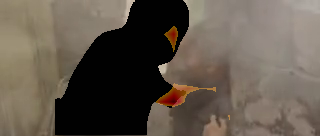

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 5.2874 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'arrest', 'reason': 'The video shows a person in a dark outfit interacting with another person against a wall. The interaction appears forceful, suggesting a possible arrest or confrontation.'}
##############################Video Clip Snippet idx 64:80##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 185.69it/s]


CLIP encoding video frames...


...

100%|██████████| 1/1 [00:00<00:00, 274.78it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 38.04it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.035224 seconds.


GRAD4VAD_XAI_PPA.predict is done!
process time: 0.1455 seconds.
==============================RESULT==============================


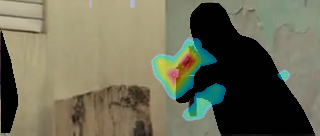

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 5.434 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'arson', 'reason': 'The video shows a person in dark clothing holding what appears to be a fire-related object near a wall, suggesting potential arson activity.'}
##############################Video Clip Snippet idx 80:96##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 156.66it/s]


CLIP encoding video frames...


...

Getting class names from labels, video_chunck_freq: 16
CLIP4VAD_XAI.inference is done!
process time: 0.19593 seconds.
==============================RESULT==============================
{'shooting': 0.58817, 'fight': 0.1626, 'nonviolence': 0.11584}
pred_anml_category: shooting, pred_anml_category_idx: 6, condidate_localized_frame_idx: 0
******************************VAD XAI using ZSAM******************************
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (136, 320, 3)
xai_cat_name: shooting, xai_class_idx: 6
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (136, 320, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 1
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 1, device: cuda, video_chunck_freq: 1, pooling_method: max
video frames preprocessing...


100%|██████████| 1/1 [00:00<00:00, 399.95it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 44.97it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.029779 seconds.
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.06484 seconds.
==============================RESULT==============================


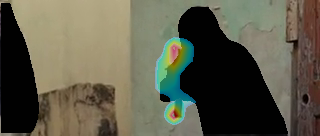

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 5.4986 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'arson', 'reason': 'The video shows silhouettes of individuals near a building with visible smoke, suggesting a potential fire or arson activity.'}
##############################Video Clip Snippet idx 96:112##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 237.92it/s]


CLIP encoding video frames...


...

Getting class names from labels, video_chunck_freq: 16
CLIP4VAD_XAI.inference is done!
process time: 0.23108 seconds.
==============================RESULT==============================
{'fight': 0.35918, 'abuse': 0.27771, 'nonviolence': 0.15232}
pred_anml_category: fight, pred_anml_category_idx: 4, condidate_localized_frame_idx: 0
******************************VAD XAI using ZSAM******************************
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (136, 320, 3)
xai_cat_name: fight, xai_class_idx: 4
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (136, 320, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 1
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 1, device: cuda, video_chunck_freq: 1, pooling_method: max
video frames preprocessing...


100%|██████████| 1/1 [00:00<00:00, 381.82it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 45.52it/s]


Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.03128 seconds.
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.06671 seconds.
==============================RESULT==============================


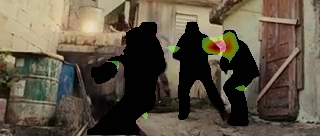

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 5.7664 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'arson', 'reason': 'The video shows silhouettes of people on a rooftop, with one person appearing to light a fire. The presence of fire and individuals in a potentially suspicious activity suggests arson.'}
##############################Video Clip Snippet idx 112:128##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 230.26it/s]


CLIP encoding video frames...


...

Getting class names from labels, video_chunck_freq: 16
CLIP4VAD_XAI.inference is done!
process time: 0.16719 seconds.
==============================RESULT==============================
{'shooting': 0.71499, 'abuse': 0.23463, 'nonviolence': 0.0253}
pred_anml_category: shooting, pred_anml_category_idx: 6, condidate_localized_frame_idx: 7
******************************VAD XAI using ZSAM******************************
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (136, 320, 3)
xai_cat_name: shooting, xai_class_idx: 6
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (136, 320, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 1
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 1, device: cuda, video_chunck_freq: 1, pooling_method: max
video frames preprocessing...


100%|██████████| 1/1 [00:00<00:00, 236.79it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 45.03it/s]


Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.031348 seconds.
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.069535 seconds.
==============================RESULT==============================


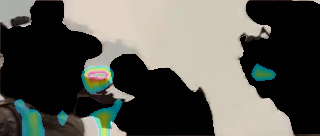

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 


ADXAIVLMInference.inference is done!
process time: 5.5467 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'arrest', 'reason': 'The video shows a person being physically restrained by another individual on a set of stairs. The actions suggest a possible arrest or detainment, indicating an abnormal security activity.'}
##############################Video Clip Snippet idx 128:144##############################


******************************VAD XAI using ZSAC******************************
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 16, device: cuda, video_chunck_freq: 16, pooling_method: max
video frames preprocessing...


100%|██████████| 16/16 [00:00<00:00, 205.03it/s]


CLIP encoding video frames...


...

Getting class names from labels, video_chunck_freq: 16
CLIP4VAD_XAI.inference is done!
process time: 0.16456 seconds.
==============================RESULT==============================
{'shooting': 0.36755, 'nonviolence': 0.18474, 'riot': 0.17687}
pred_anml_category: shooting, pred_anml_category_idx: 6, condidate_localized_frame_idx: 15
******************************VAD XAI using ZSAM******************************
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (136, 320, 3)
xai_cat_name: shooting, xai_class_idx: 6
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (136, 320, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 1
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 1, device: cuda, video_chunck_freq: 1, pooling_method: max
video frames preprocessing...


100%|██████████| 1/1 [00:00<00:00, 135.15it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 42.91it/s]

Getting class names from labels, video_chunck_freq: 1
CLIP4VAD_XAI.inference is done!
process time: 0.036146 seconds.
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.074434 seconds.
==============================RESULT==============================


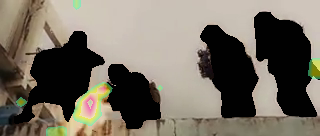

******************************VAD XAI using ZSAD******************************
ADXAIVLMInference.inference: 
Processing ADXAIVLMInference.inference: 
ADXAIVLMInference.inference is done!
process time: 5.5973 seconds.
==============================RESULT==============================
{'anomaly_status': 'YES', 'category': 'arrest', 'reason': 'The video shows multiple individuals in dark clothing, with one person appearing to be restrained by others. The scene suggests a possible arrest or detainment due to the physical interaction between the individuals.'}


In [12]:
xavad_xai_inference(video_filepath, video_frames_anonymized, is_masked_an=True, issave=True)